# Solutions for Exercise 21 (COM3502-4502-6502 Speech Processing)

In this notebook, the tasks for Exercise 21 will be solved. Please put questions, comments and correction suggestions in the Blackboard discussion board or send an email to s.goetze@sheffield.ac.uk. 

In [1]:
#necessary libraries are added
import scipy.signal as signal        #signal processing library
import numpy as np                   #math
import matplotlib.pyplot as plt      #plotting

### Task 1: Design a low-pass filter 
a)Plotting of boxcar, von hann and hamming windows in the same graph.

In [2]:
window = signal.windows.boxcar(51) 
bR = signal.firwin(50, 0.4, window='boxcar') # rectangular window
w1, hR = signal.freqz(bR, 1, 512)

In [3]:
window = signal.windows.hann(51)
bH = signal.firwin(50, 0.4, window='hann') #hann window
w2, hH  = signal.freqz(bH, 1, 512)

In [4]:
window = signal.windows.hamming(51)
bHM = signal.firwin(50,0.4, window = 'hamming') #hamming window
w3, hHM  = signal.freqz(bHM, 1, 512)


In [5]:
window = signal.windows.blackman(51)
bB = signal.firwin(50,0.4, window = 'blackman') #blackman window
w4, hB  = signal.freqz(bB, 512)

In [6]:
window = signal.windows.kaiser(51, beta = 8)
bK = signal.firwin(50,0.4, window = ('kaiser', 8)) #kaiser window 
w5, hK = signal.freqz(bK, 512)


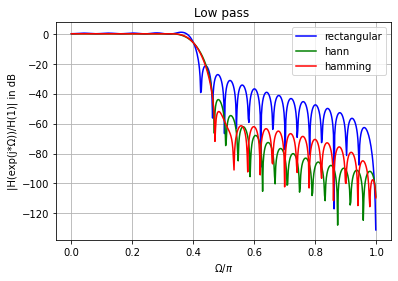

In [7]:
plt.title('Low pass ')
#np.seterr(divide = 'ignore') #RuntimeWarning: divide by zero encountered. To avoid this error, we used np.seterr
#np.seterr(divide = 'warn') 

plt.plot(w1/np.pi, 20*np.log10(np.abs(hR/max(hR))),'b', label='rectangular') #rectangular
plt.plot(w2/np.pi, 20*np.log10(np.abs(hH/max(hH))),'g', label='hann') #hann
plt.plot(w3/np.pi, 20*np.log10(np.abs(hHM/max(hHM))),'r', label='hamming') #hamming

#plt.xlabel('\u03A9/\u03C0') #omega/pi    ###these are unicode characters for greek letters.
plt.xlabel('$\Omega/\pi$')
plt.ylabel('|H(exp(j*\u03A9))/H(1)| in dB')
#plt.axis([0, 1, -150, 0])

plt.grid()
plt.legend()
plt.show()


In the figure above, the amplitude responses of the filter with order numtaps = 50 are plotted. It shows the normalized of cutoff = 0.4, which is used for rectangular(boxcar), hann and hamming window techniques. 

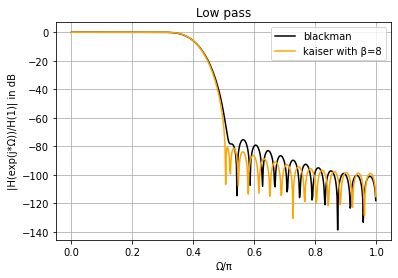

In [8]:
plt.title('Low pass')
plt.plot(w1/np.pi, 20*np.log10(np.abs(hB/max(hB))),'black', label='blackman') #blackman
plt.plot(w2/np.pi, 20*np.log10(np.abs(hK/max(hK))),'orange', label='kaiser with \u03B2=8') #kaiser with beta=8

plt.xlabel('\u03A9/\u03C0')
plt.ylabel('|H(exp(j*\u03A9))/H(1)| in dB')
#plt.axis([0, 1, -150, 0])

plt.grid()
plt.legend()
plt.show()


A comparison between the amplitude responses shows the problem of compromising the highest first shot attenuation possible and the smallest possible pass band. If we consider the trend of the Kaiser- against the Blackman-window, it is an advantage to know the free parameter. At almost similar steepness of the flank, the Kaiser-window have a small pass-band,(­S=¼ ¼ 0:5 against ­S=¼ ¼ 0; 55) and at the same time a better first shot (aN ¼ 83 dB against aN ¼ 75 dB).

### Task 2: Design a high pass filter
a)Design a high-pass filter of order m=33 and cut-off frequency Wn=0.4 using the Python function firwin() using Hamming window and plot.

In [9]:
x = signal.firwin(33, 0.4,  window='hamming', pass_zero=False) 
w, h = signal.freqz(x, 1, 512)

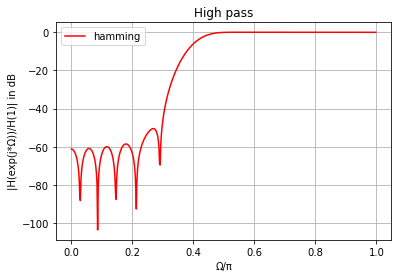

In [10]:
plt.plot(w1/np.pi, 20*np.log10(np.abs(h/max(h))),'r', label='hamming') #hamming

plt.title('High pass')
plt.xlabel('\u03A9/\u03C0')
plt.ylabel('|H(exp(j*\u03A9))/H(1)| in dB')

plt.grid()
plt.legend()
plt.show()

The portrayed trend shows the amplitude response of a high-pass with order m = 33 and a normalized
frequency limit of 0.4. A Hamming-window is used here.

### Task 3: Determine group delay
a)Group delay and linearity of a system are closely connected. Calculate and plot the group delay of the low-pass filter of Task 1 (Hamming-Window). Use the function group_delay()

In [11]:
x = signal.firwin(50, 0.4,  window='hamming')
w, h = signal.group_delay((x,256))

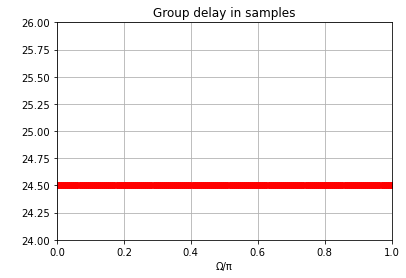

In [12]:
plt.plot(w,h, 'or') 
plt.title('Group delay in samples')
plt.xlabel('\u03A9/\u03C0')
plt.ylabel(' ')

plt.axis([0, 1, 24, 26])
plt.grid()
plt.show()

We get the plot above against the normalized frequency for the designed low-pass in exercise part Task 1.a with m = 50 (window function: Hamming)